In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
DATA_PATH = "C:/Data/Bit inf/sem 7/7th sem/ED408 SML 2 LAB/M2/world_bank_macro_2010_2023.csv"
FIGURE_DIR = ROOT / "results" / "figures"
METRIC_DIR = ROOT / "results" / "metrics"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "trade_pct_gdp", "gross_capital_formation_pct_gdp", "inflation_consumer_pct",
    "unemployment_pct", "fdi_net_inflows_pct_gdp", "government_consumption_pct_gdp",
    "industry_value_added_pct_gdp", "urban_population_pct", "population_growth_pct",
]
FEATURE_LABELS = {
    "trade_pct_gdp": "Trade (% GDP)",
    "gross_capital_formation_pct_gdp": "Capital formation (% GDP)",
    "inflation_consumer_pct": "Inflation (%)",
    "unemployment_pct": "Unemployment (%)",
    "fdi_net_inflows_pct_gdp": "FDI inflows (% GDP)",
    "government_consumption_pct_gdp": "Government consumption (% GDP)",
    "industry_value_added_pct_gdp": "Industry value added (% GDP)",
    "urban_population_pct": "Urban population (%)",
    "population_growth_pct": "Population growth (%)",
}
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

,Value
Country-year rows,2939.000000
Economies,210.000000
First year,2010.000000
Last year,2023.000000
Median GDP per capita,13769.849976


,Missing percent
population_growth_pct,2.1
unemployment_pct,2.3
trade_pct_gdp,2.4
gross_capital_formation_pct_gdp,2.4
government_consumption_pct_gdp,2.4
inflation_consumer_pct,2.6
fdi_net_inflows_pct_gdp,2.6
industry_value_added_pct_gdp,2.6
urban_population_pct,2.9


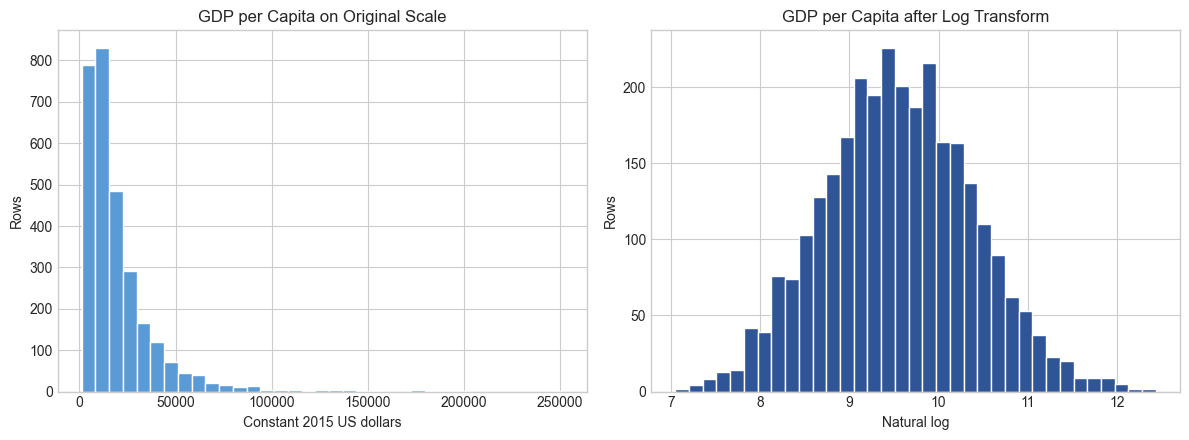

In [2]:
raw = pd.read_csv(DATA_PATH)
target = "gdp_per_capita_constant_2015_usd"
data = raw.loc[raw[target].notna() & (raw[FEATURES].notna().sum(axis=1) >= 6)].copy()
data["log_gdp_per_capita"] = np.log(data[target])

summary_table = pd.DataFrame({"Value": [
    len(data), data.country_code.nunique(), int(data.year.min()), int(data.year.max()),
    data[target].median(),
]}, index=["Country-year rows", "Economies", "First year", "Last year", "Median GDP per capita"])
display(summary_table)
display((data[FEATURES].isna().mean() * 100).sort_values().rename("Missing percent").round(1).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(data[target], bins=35, color="#5B9BD5", edgecolor="white")
axes[0].set(title="GDP per Capita on Original Scale", xlabel="Constant 2015 US dollars", ylabel="Rows")
axes[1].hist(data.log_gdp_per_capita, bins=35, color="#2F5597", edgecolor="white")
axes[1].set(title="GDP per Capita after Log Transform", xlabel="Natural log", ylabel="Rows")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_world_bank_target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

In [3]:
X, y, groups = data[FEATURES], data.log_gdp_per_capita, data.country_code
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
train_countries, test_countries = set(groups_train), set(groups_test)
assert train_countries.isdisjoint(test_countries)

display(pd.DataFrame({
    "Training": [len(X_train), len(train_countries)],
    "Testing": [len(X_test), len(test_countries)],
}, index=["Rows", "Distinct economies"]))
print("Country overlap:", len(train_countries & test_countries))

,Training,Testing
Rows,2351,588
Distinct economies,168,42


Country overlap: 0


In [4]:
alpha_grid = np.logspace(-4, 2, 25)
cv = GroupKFold(n_splits=5)
specifications = {
    "Linear Regression": (LinearRegression(), {}),
    "Lasso L1": (Lasso(max_iter=100_000), {"model__alpha": alpha_grid}),
    "Ridge L2": (Ridge(), {"model__alpha": alpha_grid}),
    "Elastic Net": (ElasticNet(max_iter=100_000), {
        "model__alpha": alpha_grid, "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    }),
}

models, selection_rows = {}, []
for name, (estimator, grid) in specifications.items():
    pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", estimator),
    ])
    search = GridSearchCV(pipeline, grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train, groups=groups_train)
    models[name] = search.best_estimator_
    selection_rows.append({"Model": name, "Best parameters": search.best_params_ or "None",
                           "Mean CV log RMSE": -search.best_score_})

selection = pd.DataFrame(selection_rows).set_index("Model")
display(selection)

,Best parameters,Mean CV log RMSE
Model,,
Linear Regression,None,0.273994
Lasso L1,{'model__alpha': 0.0031622776601683794},0.273851
Ridge L2,{'model__alpha': 5.623413251903491},0.273988
Elastic Net,"{'model__alpha': 0.005623413251903491, 'model_...",0.273854


In [5]:
rows, predictions, coefficient_values = [], {}, {}
for name, pipeline in models.items():
    pred_log = pipeline.predict(X_test)
    actual_usd, pred_usd = np.exp(y_test.to_numpy()), np.exp(pred_log)
    coef = pipeline.named_steps["model"].coef_
    predictions[name], coefficient_values[name] = pred_log, coef
    rows.append({
        "Model": name,
        "Test log RMSE": mean_squared_error(y_test, pred_log) ** 0.5,
        "Test log MAE": mean_absolute_error(y_test, pred_log),
        "Test R2": r2_score(y_test, pred_log),
        "Median absolute percentage error": np.median(np.abs(actual_usd - pred_usd) / actual_usd),
        "Nonzero coefficients": np.count_nonzero(np.abs(coef) > 1e-8),
        "Coefficient L1 norm": np.abs(coef).sum(),
        "Coefficient L2 norm": np.linalg.norm(coef),
    })
results = pd.DataFrame(rows).set_index("Model").sort_values("Test log RMSE")
display(results.round(4))
best_model = results.index[0]
print(f"Lowest held-out log RMSE: {best_model} ({results.iloc[0]['Test log RMSE']:.4f})")

,Test log RMSE,Test log MAE,Test R2,Median absolute percentage error,Nonzero coefficients,Coefficient L1 norm,Coefficient L2 norm
Model,,,,,,,
Linear Regression,0.2980,0.2326,0.9037,0.1936,9,0.9597,0.5142
Ridge L2,0.2981,0.2326,0.9036,0.1937,9,0.9594,0.5129
Lasso L1,0.2985,0.2327,0.9033,0.1934,8,0.9482,0.5136
Elastic Net,0.2987,0.2328,0.9032,0.1928,8,0.9458,0.5127


Lowest held-out log RMSE: Linear Regression (0.2980)


,Linear Regression,Lasso L1,Ridge L2,Elastic Net
Trade (% GDP),0.3226,0.3232,0.3218,0.3228
Capital formation (% GDP),0.0556,0.0541,0.0560,0.0541
Inflation (%),-0.0565,-0.0543,-0.0566,-0.0539
Unemployment (%),0.0015,0.0000,0.0013,0.0000
FDI inflows (% GDP),0.0383,0.0369,0.0387,0.0369
Government consumption (% GDP),0.0300,0.0279,0.0302,0.0275
Industry value added (% GDP),0.0456,0.0442,0.0460,0.0442
Urban population (%),0.3860,0.3859,0.3849,0.3851
Population growth (%),-0.0237,-0.0216,-0.0240,-0.0214


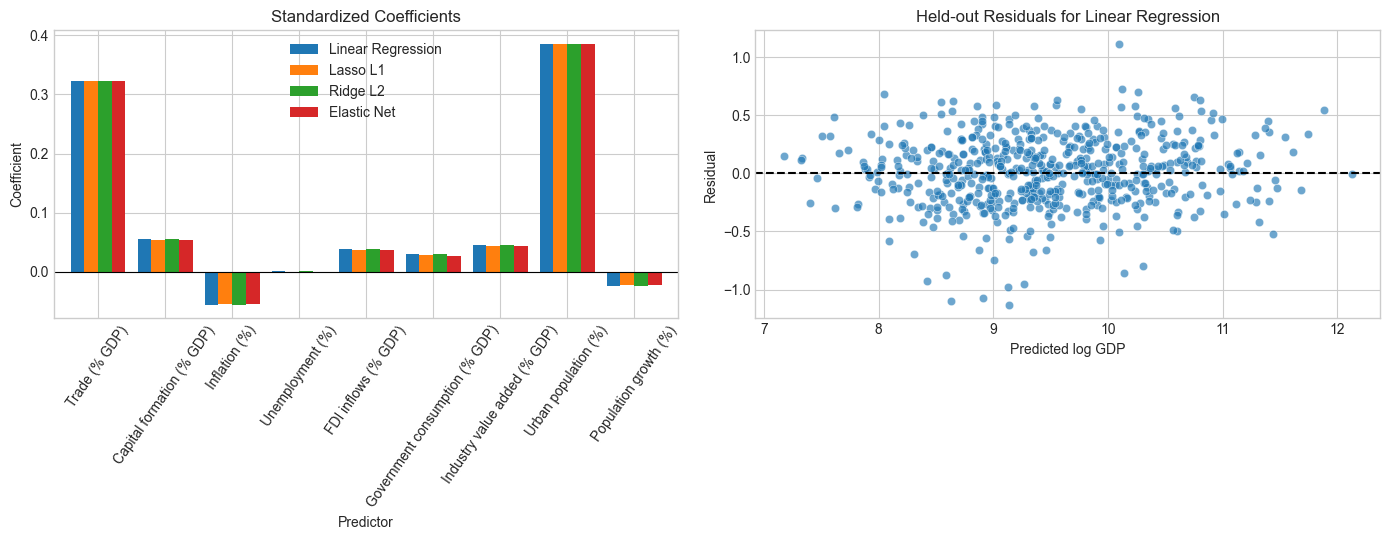

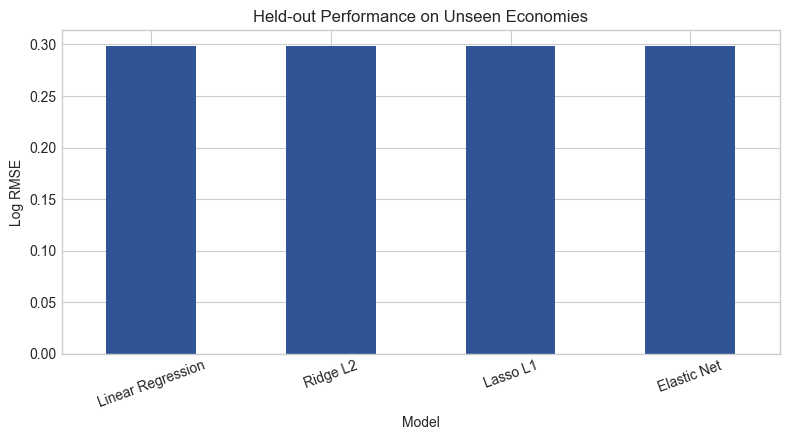

In [6]:
coefficients = pd.DataFrame(coefficient_values, index=[FEATURE_LABELS[x] for x in FEATURES])
display(coefficients.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
coefficients.plot(kind="bar", ax=axes[0], width=0.82)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Standardized Coefficients", xlabel="Predictor", ylabel="Coefficient")
axes[0].tick_params(axis="x", rotation=55)
residuals = y_test.to_numpy() - predictions[best_model]
axes[1].scatter(predictions[best_model], residuals, alpha=0.65, edgecolor="white", linewidth=0.4)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title=f"Held-out Residuals for {best_model}", xlabel="Predicted log GDP", ylabel="Residual")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_coefficients_residuals.png", dpi=180, bbox_inches="tight")
plt.show()

ax = results["Test log RMSE"].sort_values().plot(kind="bar", figsize=(8, 4.5), color="#2F5597")
ax.set(title="Held-out Performance on Unseen Economies", ylabel="Log RMSE", xlabel="Model")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

,Method,Alpha,Mean CV log RMSE,CV standard deviation,Coefficient L2 norm,Nonzero coefficients
36,Elastic Net,0.00398,0.27388,0.00937,0.51274,8
4,Lasso L1,0.00398,0.27385,0.00941,0.51354,8
28,Ridge L2,6.30957,0.27399,0.00932,0.51279,9


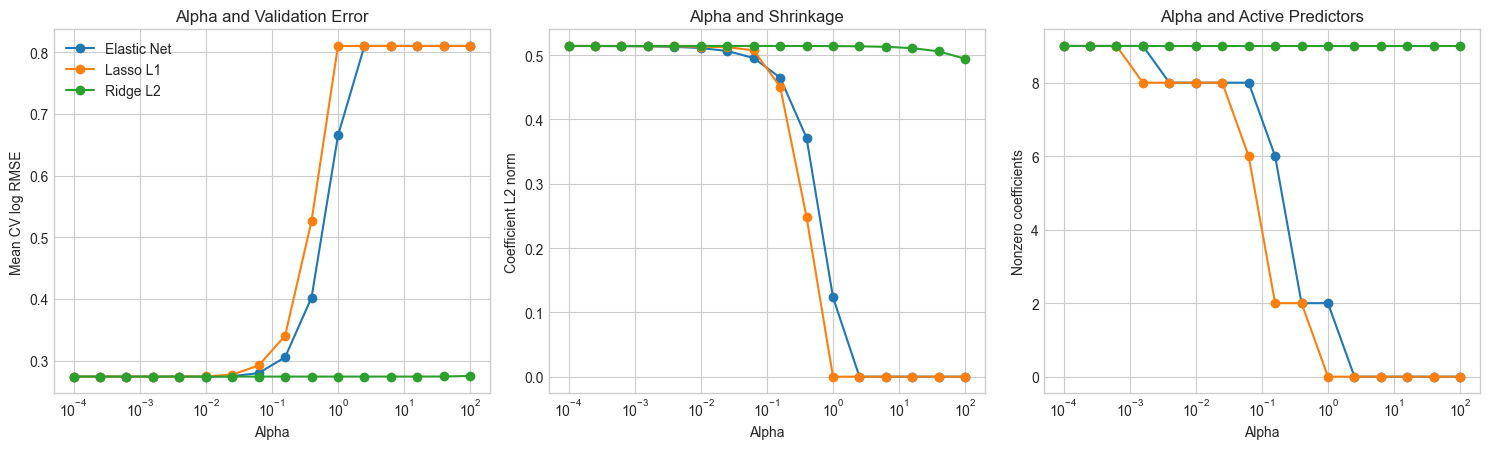

In [7]:
sensitivity_rows = []
factories = {
    "Lasso L1": lambda a: Lasso(alpha=a, max_iter=100_000),
    "Ridge L2": lambda a: Ridge(alpha=a),
    "Elastic Net": lambda a: ElasticNet(alpha=a, l1_ratio=0.5, max_iter=100_000),
}
for method, factory in factories.items():
    for alpha in np.logspace(-4, 2, 16):
        pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler()), ("model", factory(alpha))])
        scores = -cross_val_score(pipeline, X_train, y_train, groups=groups_train, cv=cv,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
        pipeline.fit(X_train, y_train)
        coef = pipeline.named_steps["model"].coef_
        sensitivity_rows.append({"Method": method, "Alpha": alpha,
            "Mean CV log RMSE": scores.mean(), "CV standard deviation": scores.std(),
            "Coefficient L2 norm": np.linalg.norm(coef),
            "Nonzero coefficients": np.count_nonzero(np.abs(coef) > 1e-8)})

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.loc[sensitivity.groupby("Method")["Mean CV log RMSE"].idxmin()].round(5))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for method, group in sensitivity.groupby("Method"):
    axes[0].semilogx(group.Alpha, group["Mean CV log RMSE"], marker="o", label=method)
    axes[1].semilogx(group.Alpha, group["Coefficient L2 norm"], marker="o", label=method)
    axes[2].semilogx(group.Alpha, group["Nonzero coefficients"], marker="o", label=method)
for axis, title, ylabel in zip(axes,
        ["Alpha and Validation Error", "Alpha and Shrinkage", "Alpha and Active Predictors"],
        ["Mean CV log RMSE", "Coefficient L2 norm", "Nonzero coefficients"]):
    axis.set(title=title, xlabel="Alpha", ylabel=ylabel)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_alpha_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

In [8]:
def scalar(value):
    return value.item() if isinstance(value, np.generic) else value

artifact = {"dataset": "World Bank World Development Indicators panel", "years": [2010, 2023],
    "rows": len(data), "economies": data.country_code.nunique(), "country_overlap": 0,
    "best_test_model": best_model, "models": {}}
for name, pipeline in models.items():
    estimator = pipeline.named_steps["model"]
    artifact["models"][name] = {
        "parameters": {k: scalar(v) for k, v in estimator.get_params().items() if k in {"alpha", "l1_ratio"}},
        **{k: scalar(v) for k, v in results.loc[name].items()},
    }
metric_path = METRIC_DIR / "q11_regularization_world_bank.json"
metric_path.write_text(json.dumps(artifact, indent=2) + "\n")

best_regularized = results.drop(index="Linear Regression")["Test log RMSE"].idxmin()
verb = "improved on" if results.loc[best_regularized, "Test log RMSE"] < results.loc["Linear Regression", "Test log RMSE"] else "did not improve on"
print(f"Conclusion: {best_regularized} was the strongest regularized model and {verb} the unregularized baseline. "
      f"Its held-out log RMSE was {results.loc[best_regularized, 'Test log RMSE']:.4f}, versus "
      f"{results.loc['Linear Regression', 'Test log RMSE']:.4f}. Stronger penalties reduced coefficient "
      "magnitudes, but excessive regularization raised validation error. The findings are predictive, not causal.")
print("Saved", metric_path.relative_to(ROOT))

Conclusion: Ridge L2 was the strongest regularized model and did not improve on the unregularized baseline. Its held-out log RMSE was 0.2981, versus 0.2980. Stronger penalties reduced coefficient magnitudes, but excessive regularization raised validation error. The findings are predictive, not causal.
Saved results\metrics\q11_regularization_world_bank.json
